In [6]:
import pandas as pd
df = pd.read_csv("D:\\BlueRose\\iffco_discount_model\\data\\aggregated_sample.csv", parse_dates=['__month__'])  # adjust filename/path
# ensure columns: month, PRODUCT_GROUP, LOCATION (if any), __amt__ or AMOUNT
# rename to consistent names:
df = df.rename(columns={'__amt__':'amount','AMOUNT':'amount','__month__':'ds','PRODUCT_GROUP':'product_group'})

# If you have location column, ensure it's named 'location'
# df = df.rename(columns={'YOUR_LOCATION_COLUMN':'location'})

# make column names unique
df = df.loc[:, ~df.columns.duplicated()]

# create time features
df['year'] = df['ds'].dt.year
df['month_of_year'] = df['ds'].dt.month
df['quarter'] = df['ds'].dt.quarter

# sort and create lags/rolling
df = df.sort_values(['product_group','ds'])
df['lag_1'] = df.groupby('product_group')['amount'].shift(1)
df['lag_3'] = df.groupby('product_group')['amount'].shift(3)
df['rmean_3'] = df.groupby('product_group')['amount'].shift(1).rolling(3).mean().reset_index(0,drop=True)
df = df.dropna(subset=['lag_1'])  # for training, remove earliest rows


Index(['amount'], dtype='object')

In [9]:
# pip install xgboost scikit-learn
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
import xgboost as xgb

# features
features = ['year','month_of_year','quarter','lag_1','lag_3','rmean_3']
X = df[features]
y = df['amount']

# time-series CV
tscv = TimeSeriesSplit(n_splits=5)
scores = []
for train_idx, test_idx in tscv.split(X):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    model = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, random_state=42)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    mae = mean_absolute_error(y_test, preds)
    scores.append(mae)
print("CV MAE per fold:", scores)
print("CV MAE mean:", sum(scores)/len(scores))


CV MAE per fold: [196.19806077752688, 110.01547129807744, 400.48249481555797, 112.99384740829467, 412.48428336713243]
CV MAE mean: 246.4348315333179


In [10]:
# pip install prophet
from prophet import Prophet

# Example for one product:
p = df[df['product_group']=='PRODUCT_A'][['ds','amount']].rename(columns={'amount':'y'}).sort_values('ds')
m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
# add holidays if you have an holidays dataframe
m.fit(p)
future = m.make_future_dataframe(periods=12, freq='M')
forecast = m.predict(future)
m.plot(forecast)


d:\BlueRose\iffco_discount_model\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ValueError: Dataframe has less than 2 non-NaN rows.

In [11]:
counts = df.groupby('product_group').size().sort_values(ascending=False)
print(counts.head(10))


product_group
Ice creams                245
Biscuits                   91
Oils                       43
Flour                      27
Chocolate                  24
Fats                       13
Frozen Bakery Products     12
Condiments - Wet           11
Confectionary              11
Snacks                      5
dtype: int64


In [12]:
good_product = counts.index[0]
print("Using product:", good_product)


Using product: Ice creams


In [13]:
p = (
    df[df['product_group'] == good_product]
      .groupby('ds')['amount'].sum()
      .reset_index()
      .rename(columns={'amount':'y'})
      .sort_values('ds')
)


10:56:25 - cmdstanpy - INFO - Chain [1] start processing
10:56:27 - cmdstanpy - INFO - Chain [1] done processing
d:\BlueRose\iffco_discount_model\venv\Lib\site-packages\prophet\forecaster.py:1872: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dates = pd.date_range(


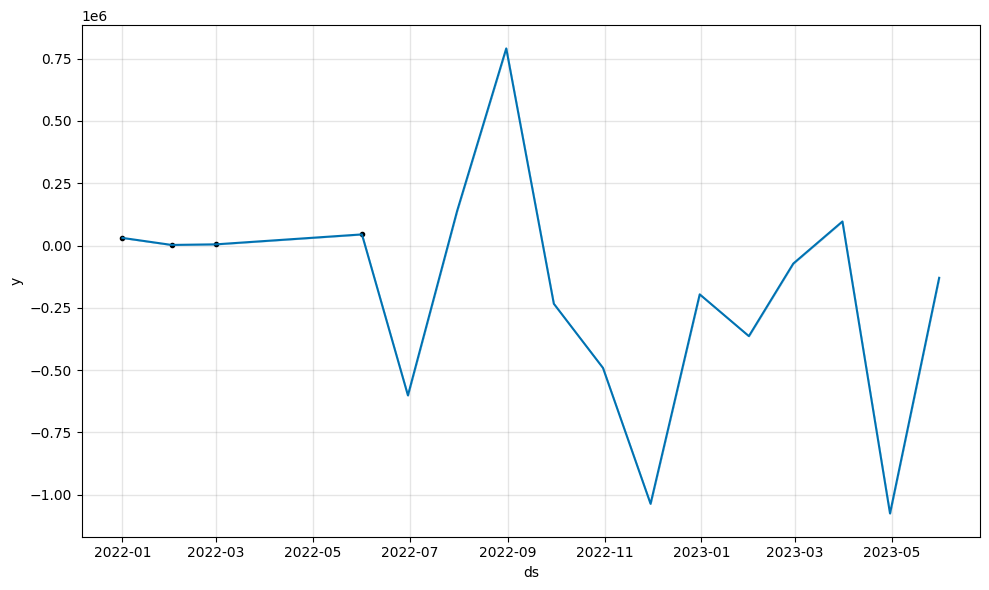

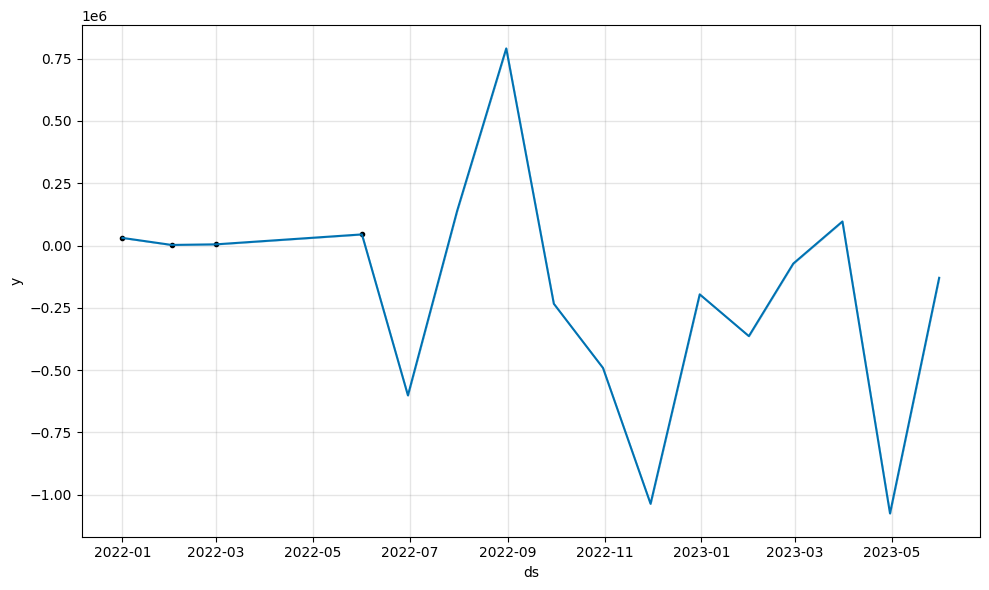

In [14]:
from prophet import Prophet

m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
m.fit(p)

future = m.make_future_dataframe(periods=12, freq='M')
forecast = m.predict(future)

m.plot(forecast)


Found 49 claim dump files in D:\BlueRose\iffco_discount_model\data\contracts_claims_extracted
Concatenated sales shape: (2115020, 87)
Sample columns: ['undo_split', 'claim_id', 'claim_date', 'month', 'geographical_cluster', 'customer_channel', 'claim_type', 'customer_name', 'ebs_party_site_id', 'amount', 'status', 'sub_status', 'original_amount', 'split_claim', 'split_flag', 'master_claim', 'comments', 'claim_details', 'period', 'reason', 'claim_number', 'ebs_header_id', 'dm_ebs_header_id', 'deal_balance_for_claim', 'company', 'location_name', 'location', 'cost_centre_code', 'profit_center', 'product_group', 'revised_amount', 'organization', 'tactics', 'tactic_type', 'deal_number', 'tactic_number', 'item_quantity', 'unit_price', 'assigned_to', 'ebs_site_id']
After forcing/renaming, columns include: ['claim_date', 'amount', 'product_group', 'location']


C:\Users\anton\AppData\Local\Temp\ipykernel_10856\2834158553.py:46: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  return pd.to_datetime(series, errors='coerce')


Rows found after UAE filter (approx): 2115020
Rows after dropping NA essentials: 2112433
Monthly aggregated shape (ds x product_group): (947, 3)
Total positive sales sum: 420168633.70609  total returns sum: 44330.33
Merged rebate fixed_rebate_amount; sample unique products with rebate >0: 48328
SIP claim-plan common columns: {'tactic_name', 'period', 'tda_plan_row_id', 'upd_date', 'tactic_number', 'month', 'tda_plan_id'}
Using join key for SIP/Tactic merge: tda_plan_id
Seasonality merged. Unique (promo_activity>0) rows: 48675
Dropped 28 rows with missing lag_1. Rows remaining for modelling: 49707
Modeling data shape: (49707, 11) n_samples: 49707
Fold 1 MAE: 83214.1997
Fold 2 MAE: 188520.7179
Fold 3 MAE: 1278905.1643
Fold 4 MAE: 766914.1278
Fold 5 MAE: 132855.8017
CV MAE per fold: [83214.19973027168, 188520.7179418596, 1278905.164281647, 766914.1278078409, 132855.80173964254]
CV MAE mean: 490082.0023002523
Trained final XGBoost model on full dataset.
Number of product_groups to forecast

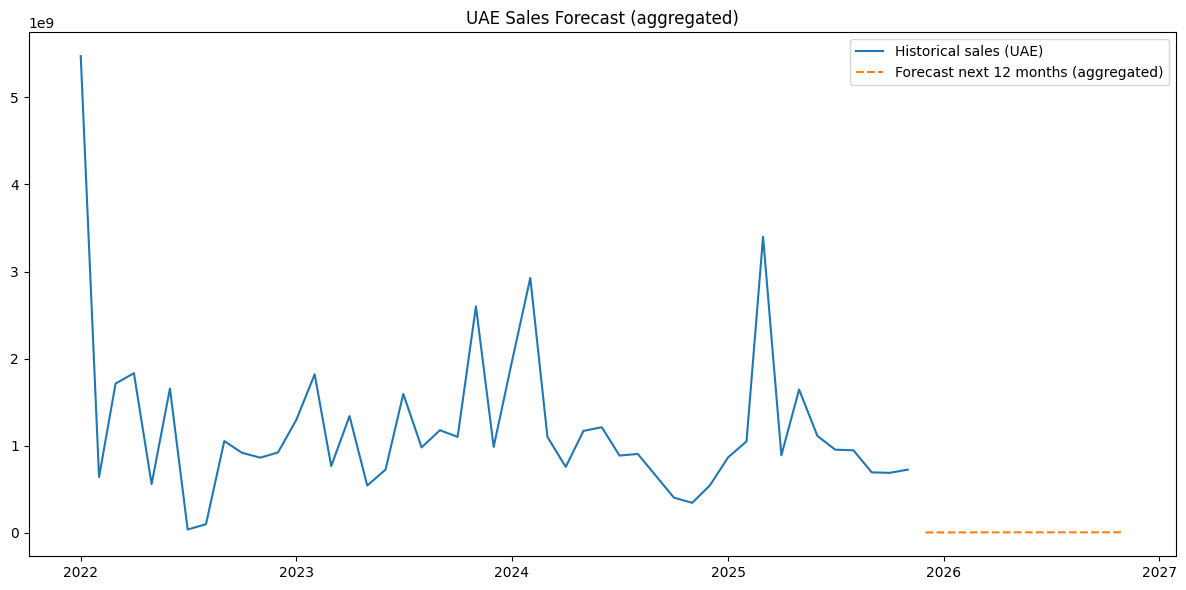

Saved model to: D:\BlueRose\iffco_discount_model\output\xgboost_sales_forecast_model.pkl
Saved model metadata to: D:\BlueRose\iffco_discount_model\output\model_metadata.pkl
Saved outputs: D:\BlueRose\iffco_discount_model\output\monthly_features.csv D:\BlueRose\iffco_discount_model\output\future_forecast_per_product.csv


In [17]:
# fixed_pipeline_uae_forecast_with_pickle.py
# Run inside your project environment. Requires pandas, numpy, xgboost, scikit-learn, matplotlib.

import os
from glob import glob
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import pickle

# -----------------------
# USER PATHS (edit if needed)
# -----------------------
claims_folder = r"D:\BlueRose\iffco_discount_model\data\contracts_claims_extracted"
sip_claim_csv = r"D:\BlueRose\iffco_discount_model\data\SIP_CLAIM_DIMNS.csv"
sip_plan_csv  = r"D:\BlueRose\iffco_discount_model\data\SIP_PLAN_DIMNS.csv"
# tactic fallback
tactic_claim_csv = r"D:\BlueRose\iffco_discount_model\data\TACTIC_CLAIMS_DIMNS.csv"
tactic_plan_csv  = r"D:\BlueRose\iffco_discount_model\data\TACTIC_PLAN_DIMNS.csv"

rebate_csv = r"D:\BlueRose\iffco_discount_model\data\Contract_Data_with_Product Group_IDS_OU_2025.csv"

out_folder = r"D:\BlueRose\iffco_discount_model\output"
os.makedirs(out_folder, exist_ok=True)
model_path = os.path.join(out_folder, "xgboost_sales_forecast_model.pkl")
meta_path = os.path.join(out_folder, "model_metadata.pkl")

# -----------------------
# HELPERS
# -----------------------
def read_file_auto(path):
    if str(path).lower().endswith('.csv'):
        return pd.read_csv(path, dtype=object)
    return pd.read_excel(path, dtype=object)

def norm_cols(df):
    df = df.copy()
    df.columns = [str(c).lower().strip() for c in df.columns]
    df = df.loc[:, ~df.columns.duplicated()]
    return df

def safe_to_datetime(series):
    return pd.to_datetime(series, errors='coerce')

# -----------------------
# STEP 1: Load & concat all claim dump files
# -----------------------
claim_files = []
for ext in ('*.xlsx','*.xls','*.csv'):
    claim_files += glob(os.path.join(claims_folder, ext))

print(f"Found {len(claim_files)} claim dump files in {claims_folder}")
if len(claim_files) == 0:
    raise SystemExit("No claim files found. Check path.")

dfs = []
for f in claim_files:
    try:
        d = read_file_auto(f)
        d = norm_cols(d)
        d['_source_file'] = os.path.basename(f)
        dfs.append(d)
    except Exception as e:
        print("Could not read", f, "->", e)

sales = pd.concat(dfs, ignore_index=True)
print("Concatenated sales shape:", sales.shape)
print("Sample columns:", sales.columns.tolist()[:40])

# -----------------------
# STEP 2: FORCE core column names (use precise known names from your data)
# -----------------------
# Your dataset contains columns: claim_date, amount, product_group, location
# If not present, we attempt reasonable fallbacks.
sales = norm_cols(sales)

if 'claim_date' not in sales.columns:
    # fallback attempt
    for c in ['created_date','date','trans_date']:
        if c in sales.columns:
            sales = sales.rename(columns={c:'claim_date'})
            break

if 'amount' not in sales.columns:
    for c in ['amt','amount_claim','original_amount','deal_balance_for_claim']:
        if c in sales.columns:
            sales = sales.rename(columns={c:'amount'})
            break

if 'product_group' not in sales.columns:
    for c in ['product_group_name','product','product_group_id']:
        if c in sales.columns:
            sales = sales.rename(columns={c:'product_group'})
            break

if 'location' not in sales.columns:
    for c in ['location_name','company','country','party_site']:
        if c in sales.columns:
            sales = sales.rename(columns={c:'location'})
            break

print("After forcing/renaming, columns include:", [c for c in ['claim_date','amount','product_group','location'] if c in sales.columns])

# -----------------------
# STEP 3: Type casting & UAE filter
# -----------------------
sales['claim_date'] = safe_to_datetime(sales.get('claim_date', pd.Series([pd.NaT]*len(sales))))
sales['amount'] = pd.to_numeric(sales.get('amount', pd.Series([np.nan]*len(sales))), errors='coerce')

# normalize product_group
if 'product_group' in sales.columns:
    sales['product_group'] = sales['product_group'].astype(str).str.strip()

# normalize location and filter UAE rows reliably
if 'country' in sales.columns:
    sales['country'] = sales['country'].astype(str).str.strip().str.upper()
    # consider different ways UAE may be written
    sales_u = sales[sales['country'].str.contains(r'\bUAE\b|\bUNITED ARAB\b|\bUNITED ARAB EMIRATES\b', regex=True, na=False)]
else:
    sales_u = sales.copy()  # if no location column, proceed (but user expects UAE-only)
print("Rows found after UAE filter (approx):", len(sales_u))

# drop rows missing essentials
sales_u = sales_u.dropna(subset=['claim_date','amount','product_group'])
print("Rows after dropping NA essentials:", len(sales_u))

if len(sales_u) == 0:
    raise SystemExit("No UAE rows after filtering. Please confirm 'location' values in your files (they might be in a different column).")

# -----------------------
# STEP 4: Monthly aggregation
# -----------------------
sales_u['ds'] = sales_u['claim_date'].dt.to_period('M').dt.to_timestamp()
monthly = (
    sales_u.groupby(['ds','product_group'])['amount']
    .sum()
    .reset_index()
    .rename(columns={'amount':'amount_raw'})
)
print("Monthly aggregated shape (ds x product_group):", monthly.shape)

# -----------------------
# STEP 5: Stabilize target (keep positive sales; returns separately)
# -----------------------
monthly['sales_pos'] = monthly['amount_raw'].clip(lower=0)
monthly['returns_abs'] = (-monthly['amount_raw'].clip(upper=0))
print("Total positive sales sum:", monthly['sales_pos'].sum(), " total returns sum:", monthly['returns_abs'].sum())

# -----------------------
# STEP 6: Rebate merge (use fixed_rebate_amount if present)
# -----------------------
monthly['rebate_amount'] = 0.0
if os.path.exists(rebate_csv):
    rebate = pd.read_csv(rebate_csv, dtype=object)
    rebate = norm_cols(rebate)
    # try to find a fixed rebate amount column
    rebate_amt_col = None
    for cand in ['fixed_rebate_amount','fixed_rebate','rebate_amount','fixed_rebate_amt','fixed_rebate_amount']:
        if cand in rebate.columns:
            rebate_amt_col = cand
            break
    product_key = None
    for cand in ['product_group','product','product_group_id','sku']:
        if cand in rebate.columns:
            product_key = cand
            break
    if rebate_amt_col and product_key:
        rebate = rebate[[product_key, rebate_amt_col]].drop_duplicates()
        rebate = rebate.rename(columns={product_key:'product_group', rebate_amt_col:'fixed_rebate_amount'})
        rebate['product_group'] = rebate['product_group'].astype(str).str.strip()
        rebate['fixed_rebate_amount'] = pd.to_numeric(rebate['fixed_rebate_amount'], errors='coerce').fillna(0)
        monthly = monthly.merge(rebate, on='product_group', how='left')
        monthly['fixed_rebate_amount'] = monthly['fixed_rebate_amount'].fillna(0)
        print("Merged rebate fixed_rebate_amount; sample unique products with rebate >0:", (monthly['fixed_rebate_amount']>0).sum())
    else:
        print("Could not detect fixed rebate columns automatically. Setting rebate to 0.")
        monthly['fixed_rebate_amount'] = 0.0
else:
    print("Rebate file not found at:", rebate_csv)
    monthly['fixed_rebate_amount'] = 0.0

# -----------------------
# STEP 7: Build seasonality/promo_activity using SIP_CLAIM_DIMNS + SIP_PLAN_DIMNS (or TACTIC fallback)
# -----------------------
def build_seasonality_from_sip(claim_csv_path, plan_csv_path):
    if not (os.path.exists(claim_csv_path) and os.path.exists(plan_csv_path)):
        return None
    c = pd.read_csv(claim_csv_path, dtype=object)
    p = pd.read_csv(plan_csv_path, dtype=object)
    c = norm_cols(c); p = norm_cols(p)
    common = set(c.columns).intersection(set(p.columns))
    print("SIP claim-plan common columns:", common)
    # Prefer likely key names
    join_key = None
    for k in ['tda_plan_id','sip_id','plan_id','tda_plan_row_id','tdaplanid','planid']:
        if k in common:
            join_key = k
            break
    if join_key is None:
        # fallback to any common column that looks like an id
        for k in common:
            if 'id' in k or 'code' in k:
                join_key = k
                break
    if join_key is None:
        print("No reliable join key found between claim and plan tables.")
        return None
    print("Using join key for SIP/Tactic merge:", join_key)
    # find product_group column in plan table
    prod_col = None
    for cand in ['product_group','product','product_group_name','product_group_id','sku']:
        if cand in p.columns:
            prod_col = cand
            break
    if prod_col is None:
        print("Could not find product_group in plan table.")
        return None
    # merge
    merged = c.merge(p[[join_key, prod_col]].drop_duplicates(), on=join_key, how='left')
    merged = merged.rename(columns={prod_col:'product_group'})
    # find date column in merged
    date_cand = None
    for cand in ['created_date','claim_date','date','start_date','end_date','upd_date']:
        if cand in merged.columns:
            date_cand = cand
            break
    if date_cand is None:
        print("No date column found in merged SIP table.")
        return None
    merged['date'] = pd.to_datetime(merged[date_cand], errors='coerce')
    merged = merged.dropna(subset=['date','product_group'])
    merged['product_group'] = merged['product_group'].astype(str).str.strip()
    merged['month'] = merged['date'].dt.month
    season = merged.groupby(['product_group','month']).size().reset_index(name='promo_activity')
    return season

seasonality = build_seasonality_from_sip(sip_claim_csv, sip_plan_csv)
if seasonality is None:
    print("SIP-based seasonality not available; trying TACTIC fallback.")
    seasonality = build_seasonality_from_sip(tactic_claim_csv, tactic_plan_csv)

if seasonality is None:
    print("No seasonality built; setting promo_activity=0")
    monthly['promo_activity'] = 0
else:
    monthly['month'] = monthly['ds'].dt.month
    monthly = monthly.merge(seasonality, on=['product_group','month'], how='left')
    monthly['promo_activity'] = monthly['promo_activity'].fillna(0)
    print("Seasonality merged. Unique (promo_activity>0) rows:", (monthly['promo_activity']>0).sum())

# -----------------------
# STEP 8: Feature engineering - lags & rolling means
# -----------------------
monthly = monthly.sort_values(['product_group','ds']).reset_index(drop=True)
if 'product_group' not in monthly.columns:
    raise SystemExit("product_group missing from monthly — cannot continue.")

for lag in [1,2,3,6]:
    monthly[f'lag_{lag}'] = monthly.groupby('product_group')['sales_pos'].shift(lag)

monthly['rmean_3'] = monthly.groupby('product_group')['sales_pos'].shift(1).rolling(3).mean().reset_index(level=0, drop=True)
monthly['rmean_6'] = monthly.groupby('product_group')['sales_pos'].shift(1).rolling(6).mean().reset_index(level=0, drop=True)

before_drop = len(monthly)
monthly = monthly.dropna(subset=['lag_1'])
after_drop = len(monthly)
print(f"Dropped {before_drop - after_drop} rows with missing lag_1. Rows remaining for modelling: {after_drop}")

# add time features
monthly['year'] = monthly['ds'].dt.year
monthly['quarter'] = monthly['ds'].dt.quarter

# -----------------------
# STEP 9: Modeling - prepare features and safe CV
# -----------------------
features = ['year','month','quarter','fixed_rebate_amount' if 'fixed_rebate_amount' in monthly.columns else 'fixed_rebate_amount',
            'promo_activity','lag_1','lag_2','lag_3','lag_6','rmean_3','rmean_6']

# ensure rebate column name in features exists as numeric
if 'fixed_rebate_amount' not in monthly.columns:
    monthly['fixed_rebate_amount'] = monthly.get('fixed_rebate_amount', 0.0).astype(float)
monthly['promo_activity'] = monthly.get('promo_activity', 0).astype(float)

# fill any remaining NANs in feature cols
for f in features:
    if f not in monthly.columns:
        monthly[f] = 0.0
monthly[features] = monthly[features].astype(float)

X = monthly[features]
y = monthly['sales_pos'].astype(float)

n_samples = len(X)
print("Modeling data shape:", X.shape, "n_samples:", n_samples)
if n_samples < 10:
    raise SystemExit("Not enough samples after preprocessing to run TimeSeries CV. Need >=10 rows.")

# choose safe n_splits
n_splits = 5 if n_samples >= 50 else 2 if n_samples < 20 else 3
tscv = TimeSeriesSplit(n_splits=n_splits)
cv_maes = []
fold = 0
for train_idx, test_idx in tscv.split(X):
    fold += 1
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    model = xgb.XGBRegressor(n_estimators=700, learning_rate=0.05, max_depth=7, random_state=42, verbosity=0)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    mae = mean_absolute_error(y_test, preds)
    cv_maes.append(mae)
    print(f"Fold {fold} MAE: {mae:.4f}")

print("CV MAE per fold:", cv_maes)
print("CV MAE mean:", float(np.mean(cv_maes)))

# train final model on full data
final_model = xgb.XGBRegressor(n_estimators=700, learning_rate=0.05, max_depth=7, random_state=42, verbosity=0)
final_model.fit(X, y)
print("Trained final XGBoost model on full dataset.")

# -----------------------
# STEP 10: Forecast next 12 months (iterative per product)
# -----------------------
last = monthly.sort_values(['product_group','ds']).groupby('product_group').tail(1).reset_index(drop=True)
if last.empty:
    raise SystemExit("No last row per product_group found. Aborting forecast.")
print("Number of product_groups to forecast:", len(last))

future_months = pd.date_range(monthly['ds'].max() + pd.offsets.MonthBegin(), periods=12, freq='MS')

# iterative month-by-month prediction per product to update lags properly
future_rows = []
for _, row in last.iterrows():
    prod = row['product_group']
    state = row.copy()  # includes lag_1.., sales_pos etc.
    for ds in future_months:
        new = state.copy()
        new['ds'] = ds
        new['year'] = ds.year
        new['month'] = ds.month
        new['quarter'] = ds.quarter
        # prepare input feature vector
        inp = pd.DataFrame([new[features].astype(float).values], columns=features)
        pred = final_model.predict(inp)[0]
        new['forecast_sales'] = float(pred)
        # append result
        future_rows.append(new.to_dict())
        # shift lags for next month
        # new lag propagation: lag_6 <- lag_5 (if exists) else keep; lag_3 <- lag_2; lag_2 <- lag_1; lag_1 <- predicted value
        for l in [6,5,4]:
            if f'lag_{l-1}' in state.index and f'lag_{l}' in state.index:
                state[f'lag_{l}'] = state.get(f'lag_{l-1}', 0)
        if 'lag_3' in state.index:
            state['lag_3'] = state.get('lag_2', 0)
        if 'lag_2' in state.index:
            state['lag_2'] = state.get('lag_1', 0)
        state['lag_1'] = pred
        # recompute rolling means
        state['rmean_3'] = np.mean([state.get('lag_1',0), state.get('lag_2',0), state.get('lag_3',0)])
        state['rmean_6'] = np.mean([state.get('lag_1',0), state.get('lag_2',0), state.get('lag_3',0), state.get('lag_6',0)])
        # keep promo_activity and fixed_rebate_amount same as last seen
        # loop continues to next ds

future_df = pd.DataFrame(future_rows)
print("Future forecast rows:", future_df.shape)

# aggregate for plot
hist = monthly.groupby('ds')['sales_pos'].sum().reset_index()
agg_future = future_df.groupby('ds')['forecast_sales'].sum().reset_index()

plt.figure(figsize=(12,6))
plt.plot(hist['ds'], hist['sales_pos'], label='Historical sales (UAE)')
plt.plot(agg_future['ds'], agg_future['forecast_sales'], '--', label='Forecast next 12 months (aggregated)')
plt.legend()
plt.title("UAE Sales Forecast (aggregated)")
plt.tight_layout()
plt.show()

# -----------------------
# STEP 11: Save artifacts & metadata (pickle)
# -----------------------
with open(model_path, "wb") as f:
    pickle.dump(final_model, f)
print("Saved model to:", model_path)

meta = {
    "features": features,
    "train_start": str(monthly['ds'].min()),
    "train_end": str(monthly['ds'].max()),
    "cv_mae_mean": float(np.mean(cv_maes)),
    "n_train_rows": int(n_samples)
}
with open(meta_path, "wb") as f:
    pickle.dump(meta, f)
print("Saved model metadata to:", meta_path)

monthly_out = os.path.join(out_folder, "monthly_features.csv")
future_out = os.path.join(out_folder, "future_forecast_per_product.csv")
monthly.to_csv(monthly_out, index=False)
future_df.to_csv(future_out, index=False)
print("Saved outputs:", monthly_out, future_out)
